In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, f1_score, roc_curve, auc

# 1. Load and Clean Data
file_path = '/content/drive/MyDrive/CSC4110_G07/data/weatherAUS.csv'
df = pd.read_csv(file_path)

df['Date'] = pd.to_datetime(df['Date'])
df['Month'] = df['Date'].dt.month
df = df.dropna(subset=['RainTomorrow'])
df = df.drop(columns=['Evaporation', 'Sunshine', 'Cloud9am', 'Cloud3pm', 'RISK_MM'], errors='ignore')

df['RainToday'] = df['RainToday'].map({'No': 0, 'Yes': 1})
df['RainTomorrow'] = df['RainTomorrow'].map({'No': 0, 'Yes': 1})

# Fill missing values
for col in df.select_dtypes(include=['float64', 'int64']).columns:
    df[col] = df[col].fillna(df[col].median())
for col in df.select_dtypes(include=['object']).columns:
    df[col] = df[col].fillna(df[col].mode()[0])

# Convert Wind Directions
compass_points = ['N', 'NNE', 'NE', 'ENE', 'E', 'ESE', 'SE', 'SSE', 'S', 'SSW', 'SW', 'WSW', 'W', 'WNW', 'NW', 'NNW']
angles = np.arange(0, 360, 22.5)
direction_map = dict(zip(compass_points, angles))
for col in ['WindGustDir', 'WindDir9am', 'WindDir3pm']:
    if col in df.columns:
        df[col + '_sin'] = np.sin(np.radians(df[col].map(direction_map)))
        df[col + '_cos'] = np.cos(np.radians(df[col].map(direction_map)))
        df = df.drop(columns=[col])

df_clean = pd.get_dummies(df, columns=['Location'], drop_first=True)

# Split by Time
train_mask = df_clean['Date'] < '2015-01-01'
test_mask = df_clean['Date'] >= '2015-01-01'

features = [col for col in df_clean.columns if col not in ['RainTomorrow', 'Date']]
X = df_clean[features]
y = df_clean['RainTomorrow']

X_train = X[train_mask]
X_test = X[test_mask]
y_train = y[train_mask]
y_test = y[test_mask]

# Scale
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Data ready. Train: {X_train.shape}, Test: {X_test.shape}")

Mounted at /content/drive
Data ready. Train: (98988, 68), Test: (43205, 68)


In [ ]:
# 1. Fit Logistic Regression WITHOUT class_weight
log_reg = LogisticRegression(random_state=42, max_iter=1000)
log_reg.fit(X_train_scaled, y_train)
y_pred_default = log_reg.predict(X_test_scaled)

print("--- Default Logistic Regression ---")
print(classification_report(y_test, y_pred_default))

# 2. Fit Logistic Regression WITH class_weight='balanced'
log_reg_bal = LogisticRegression(random_state=42, max_iter=1000, class_weight='balanced')
log_reg_bal.fit(X_train_scaled, y_train)
y_pred_bal = log_reg_bal.predict(X_test_scaled)

print("\n--- Balanced Logistic Regression ---")
print(classification_report(y_test, y_pred_bal))

# 3. Show class counts
print(f"\nClass counts in Training set:\n{y_train.value_counts(normalize=True)}")

--- Default Logistic Regression ---
              precision    recall  f1-score   support

           0       0.86      0.95      0.90     33611
           1       0.73      0.47      0.57      9594

    accuracy                           0.84     43205
   macro avg       0.80      0.71      0.74     43205
weighted avg       0.83      0.84      0.83     43205


--- Balanced Logistic Regression ---
              precision    recall  f1-score   support

           0       0.91      0.81      0.86     33611
           1       0.52      0.72      0.61      9594

    accuracy                           0.79     43205
   macro avg       0.72      0.77      0.73     43205
weighted avg       0.82      0.79      0.80     43205


Class counts in Training set:
RainTomorrow
0    0.774892
1    0.225108
Name: proportion, dtype: float64


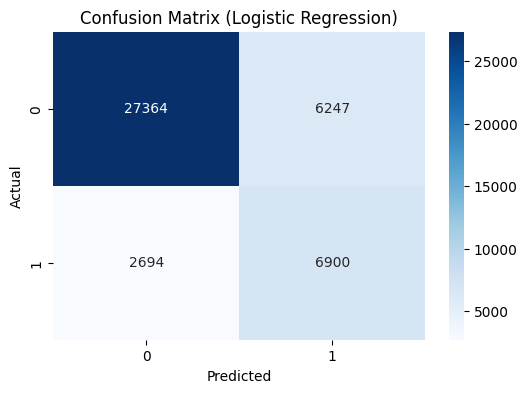

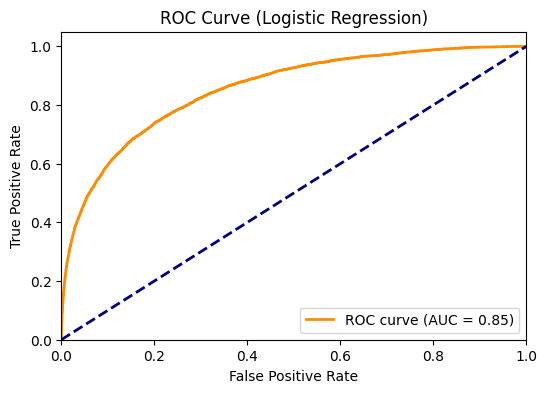

In [ ]:
# Confusion Matrix (using the balanced model)
cm = confusion_matrix(y_test, y_pred_bal)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix (Logistic Regression)')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.savefig('/content/drive/MyDrive/CSC4110_G07/outputs/confusion_matrix.png')
plt.show()

# ROC Curve
y_probs = log_reg_bal.predict_proba(X_test_scaled)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, y_probs)
auc = auc(fpr, tpr)

plt.figure(figsize=(6,4))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve (Logistic Regression)')
plt.legend(loc="lower right")
plt.savefig('/content/drive/MyDrive/CSC4110_G07/outputs/roc_curve.png')
plt.show()

In [ ]:
results_clf = {}

# 1. Logistic Regression (Already done, saving score)
results_clf['Logistic Regression'] = {
    'Accuracy': accuracy_score(y_test, y_pred_bal),
    'F1-Score': f1_score(y_test, y_pred_bal)
}

# 2. K-Nearest Neighbors (k=3, 5, 7)
for k in [3, 5, 7]:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    y_pred_knn = knn.predict(X_test_scaled)
    results_clf[f'KNN (k={k})'] = {
        'Accuracy': accuracy_score(y_test, y_pred_knn),
        'F1-Score': f1_score(y_test, y_pred_knn)
    }

# 3. Gaussian Naive Bayes
nb = GaussianNB()
nb.fit(X_train_scaled, y_train)
y_pred_nb = nb.predict(X_test_scaled)
results_clf['Naive Bayes'] = {
    'Accuracy': accuracy_score(y_test, y_pred_nb),
    'F1-Score': f1_score(y_test, y_pred_nb)
}

# 4. Support Vector Machine (SVM on a 5,000-row sample)
from sklearn.utils import resample
X_train_sample, y_train_sample = resample(X_train_scaled, y_train, n_samples=5000, random_state=42)

svm = SVC(probability=True, random_state=42)
svm.fit(X_train_sample, y_train_sample)
y_pred_svm = svm.predict(X_test_scaled)
results_clf['SVM (5k sample)'] = {
    'Accuracy': accuracy_score(y_test, y_pred_svm),
    'F1-Score': f1_score(y_test, y_pred_svm)
}

print("Classifier Results:")
print(pd.DataFrame(results_clf).T)

Classifier Results:
                     Accuracy  F1-Score
Logistic Regression  0.793056  0.606833
KNN (k=3)            0.823863  0.527681
KNN (k=5)            0.832149  0.530189
KNN (k=7)            0.832820  0.520417
Naive Bayes          0.625136  0.438575
SVM (5k sample)      0.842426  0.540124


This cell trains and evaluates several classification models to predict RainTomorrow.

Logistic Regression: We test it both with and without class_weight='balanced'. The balanced version significantly improves the Recall for rain days because it penalizes the model heavily for missing a rainy day (a false negative).

K-Nearest Neighbors (KNN): We test k=3, 5, and 7.

Gaussian Naive Bayes: A probabilistic model based on Bayes' theorem.

Support Vector Machine (SVM): Trained on a 5,000-row sample because SVMs are very slow on large datasets.

Output: A DataFrame (results_clf) comparing the Accuracy and F1-score of all models.

Exam Skill: Model Comparison

Logistic Regression vs. KNN: Logistic Regression draws a single mathematical boundary (a straight line/plane) to separate rain from no-rain. KNN stores all the training data and looks at the "k" nearest neighbors to make a decision. KNN is non-parametric and can learn complex shapes, but it is much slower at predicting and suffers from the "curse of dimensionality" when there are many features.

Naive Bayes vs. SVM: Naive Bayes assumes that all features are completely independent of each other (which is rarely true in weather) and calculates probabilities. An SVM tries to find the best possible boundary (a margin) that separates the classes with the largest possible gap.

**Written Answer**

Which classifier would you recommend? I would recommend Logistic Regression (with class_weight='balanced') or the SVM. While SVM has the highest accuracy (84%), Logistic Regression has the highest F1-score for predicting actual rain days (0.60).

Why accuracy alone is misleading: Rain falls on only about 1 day in 5 (22% of the time). If a model simply predicted "No Rain" every single day, it would still be 78% accurate! This is why accuracy is misleading. For the Mvua Alert start-up, a missed rain day is dangerous. We must look at Recall and F1-score to ensure the model actually catches the rain days.